<a href="https://colab.research.google.com/github/wllamjp/NSDC-NBA-Analysis/blob/main/Eras%20%26%20Pace/E%26P_matchup_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EDA: Matchup Edges Across Eras

The question: Do some teams consistently do better against specific opponents than expected, and does that hold in every era?

The data: q1_games_clean.csv, cleaned from FiveThirtyEight's NBA Elo data and
NBA regular season, 1979-80 to 2014-15.

We follow six questions:
1. What does one row mean?
2. Is anything missing or broken?
3. What does each variable look like on its own?
4. How do groups compare?
5. Does it change over time?
6. What should we ask next?

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
INK, GRAY = "#0b0b0b", "#898781"

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "font.size": 11,
})

nba = pd.read_csv("q1_games_clean.csv")

print(nba.shape)
print(nba.columns)

(39620, 15)
Index(['game_id', 'year_id', 'franchise_id', 'opp_franchise_id',
       'game_location', 'pts', 'opp_pts', 'forecast', 'win', 'edge', 'era',
       'game_avg_pts', 'league_avg_pts', 'pts_vs_league', 'opp_pts_vs_league'],
      dtype='object')


In [23]:
# Question 1: What does one row mean?
print(nba[['game_id', 'year_id', 'franchise_id', 'opp_franchise_id',
       'game_location', 'pts', 'opp_pts', 'forecast', 'win', 'edge', 'era',
       'game_avg_pts', 'league_avg_pts', 'pts_vs_league', 'opp_pts_vs_league']].head(4))

print("Rows per game:", nba.groupby("game_id").size().unique())
nba.groupby("year_id")["game_id"].nunique()

        game_id  year_id franchise_id opp_franchise_id game_location  pts  \
0  197910120ATL     1980        Hawks           Knicks             H  121   
1  197910120BOS     1980      Celtics          Rockets             H  114   
2  197910120DET     1980       Pacers          Pistons             A  105   
3  197910120KCK     1980        Bucks            Kings             A  103   

   opp_pts  forecast  win      edge        era  game_avg_pts  league_avg_pts  \
0      104  0.800678    1  0.199322  1980-1994         112.5      109.334257   
1      106  0.449544    1  0.550456  1980-1994         110.0      109.334257   
2      114  0.423580    0 -0.423580  1980-1994         109.5      109.334257   
3      105  0.395580    0 -0.395580  1980-1994         104.0      109.334257   

   pts_vs_league  opp_pts_vs_league  
0      11.665743          -5.334257  
1       4.665743          -3.334257  
2      -4.334257           4.665743  
3      -6.334257          -4.334257  
Rows per game: [1]


,game_id
year_id,
1980,902
1981,943
1982,943
1983,943
1984,943
1985,943
1986,943
1987,943
1988,943


Observations:
- One row is one game between two opposing teams, and each game appears only once because the duplicates were removed in cleaning.
- The amount of games played per season starts at approximately 902 and steadily increases all the way to 1228 as new teams joined, with a few outliers we can spot.
- 1999 and 2012 have fewer games due to labor disputes between team owners and the National Basketball Players Association, so the season was shortened.

In [24]:
# Question 2: Is anything missing or broken?
missing = nba.isna().sum()
print(missing[missing > 0]) # empty list indicates no missing values were found

print("forecast range:", nba["forecast"].min(), "to", nba["forecast"].max())
print("edge range:", nba["edge"].min(), "to", nba["edge"].max())
print("Does every game have a winner?", (nba["pts"] != nba["opp_pts"]).all())

# compare to an independent source (per_games.csv)
bbref = pd.read_csv("per_game.csv")
bbref["year_id"] = bbref["Season"].str[:4].astype(int) + 1
my_data = nba.groupby("year_id")["league_avg_pts"].mean().reset_index()
check = pd.merge(my_data, bbref[["year_id", "PTS"]], on = "year_id")
check["gap"] = check["league_avg_pts"] - check["PTS"]
check.round(3)

Series([], dtype: int64)
forecast range: 0.021097481 to 0.97609937
edge range: -0.96827829 to 0.972907364
Does every game have a winner? True


,year_id,league_avg_pts,PTS,gap
0,1980,109.334,109.3,0.034
1,1981,108.105,108.1,0.005
2,1982,108.577,108.6,-0.023
3,1983,108.514,108.5,0.014
4,1984,110.110,110.1,0.010
5,1985,110.838,110.8,0.038
6,1986,110.220,110.2,0.020
7,1987,109.935,109.9,0.035
8,1988,108.162,108.2,-0.038
9,1989,109.169,109.2,-0.031


Observations:
- There are no missing values in the cleaned data.
- Forecast stays between 0 and 1 (probability), edge stays between -1 and 1 (win, either 0 or 1, minus forecast), and every game has a winner because there are no ties in the NBA (only overtime in certain situations).
- Our league average points match Brandon's Basketball Reference within a 0.1 margin for each season, indicating that our cleaned data is reliable.

count    39620.000
mean         0.003
std          0.448
min         -0.968
25%         -0.376
50%         -0.048
75%          0.382
max          0.973
Name: edge, dtype: float64


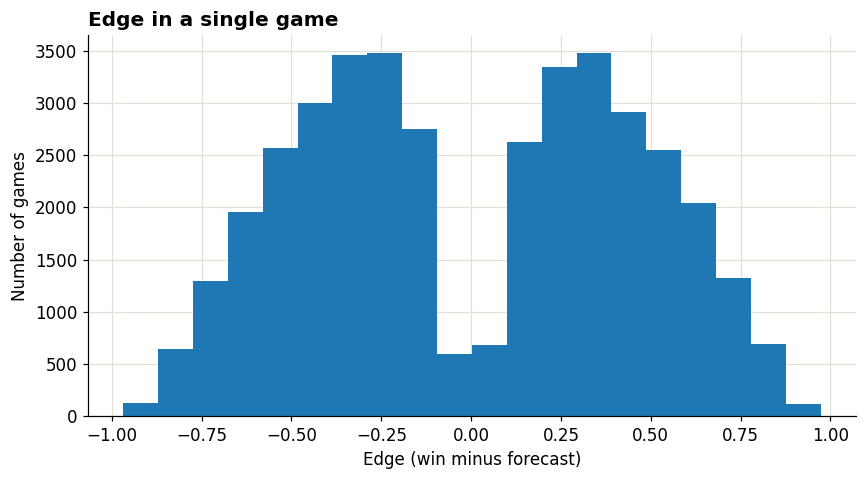

In [25]:
# Question 3: What does each variable look like on its own?

print(nba["edge"].describe().round(3))

plt.hist(nba["edge"], bins = 20)
plt.title("Edge in a single game")
plt.xlabel("Edge (win minus forecast)")
plt.ylabel("Number of games")
plt.show()

Observations:
- The average edge is 0.003, which is very close to 0. This indicates that teams do about as well as the forecast predicts.
- The histogram appears to have two humps with a dip in the middle. A win always gives a positive edge and a loss always gives a negative edge, so a single game can't land near 0.

In [26]:
# Question 4: How do groups compare?

print(nba.groupby("era")["edge"].agg(["count", "mean", "std"]).round(3))

nba["pair"] = nba["franchise_id"] + " vs " + nba["opp_franchise_id"]
pairs = nba.groupby(["pair", "year_id", "era"]).agg(games = ("game_id", "count"), avg_edge = ("edge", "mean")).reset_index()

print(pairs.shape)
pairs.head()

           count   mean    std
era                           
1980-1994  15002  0.004  0.441
1995-2004  11335 -0.000  0.450
2005-2015  13283  0.004  0.455
(12974, 5)


,pair,year_id,era,games,avg_edge
0,Bucks vs Bulls,1980,1980-1994,6,0.157035
1,Bucks vs Bulls,1981,1980-1994,6,-0.203141
2,Bucks vs Bulls,1982,1980-1994,6,0.125560
3,Bucks vs Bulls,1983,1980-1994,6,0.094553
4,Bucks vs Bulls,1984,1980-1994,6,-0.070328


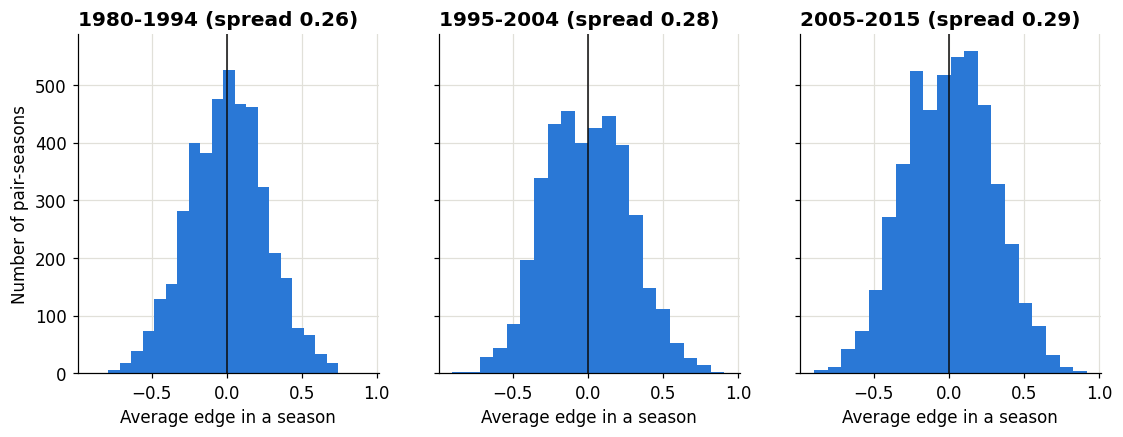

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
eras = ["1980-1994", "1995-2004", "2005-2015"]

for ax, era in zip(axes, eras):
    values = pairs[pairs["era"] == era]["avg_edge"]
    ax.hist(values, bins=20, color=BLUE)
    ax.axvline(0, color=INK, linewidth=1)
    ax.set_title(f"{era} (spread {values.std():.2f})")
    ax.set_xlabel("Average edge in a season")

axes[0].set_ylabel("Number of pair-seasons")
plt.savefig("era_histograms.png", bbox_inches="tight")
plt.show()

In [28]:
pairs.groupby("era").agg(pair_seasons = ("avg_edge", "count"), avg_games = ("games", "mean"), spread = ("avg_edge", "std")).round(3)

,pair_seasons,avg_games,spread
era,,,
1980-1994,4310,3.481,0.258
1995-2004,3879,2.922,0.276
2005-2015,4785,2.776,0.288


Observations:
- Average edge is close to 0 in every era, so most teams match their forecast.
- Averaging the edge over each pair's games within a season turns the original two-hump visualization into one hump (centered at 0)
- Spread of edges gets wider in later eras.

In [29]:
# Question 5: Does it change over time?

next_season = pairs[["pair", "year_id", "avg_edge"]].copy()
next_season["year_id"] = next_season["year_id"] - 1
next_season = next_season.rename(columns = {"avg_edge": "next_edge"})

both = pd.merge(pairs, next_season, on=["pair", "year_id"])
print(both.shape)
both[["pair", "year_id", "avg_edge", "next_edge"]].head()

(12413, 6)


,pair,year_id,avg_edge,next_edge
0,Bucks vs Bulls,1980,0.157035,-0.203141
1,Bucks vs Bulls,1981,-0.203141,0.125560
2,Bucks vs Bulls,1982,0.125560,0.094553
3,Bucks vs Bulls,1983,0.094553,-0.070328
4,Bucks vs Bulls,1984,-0.070328,-0.250009


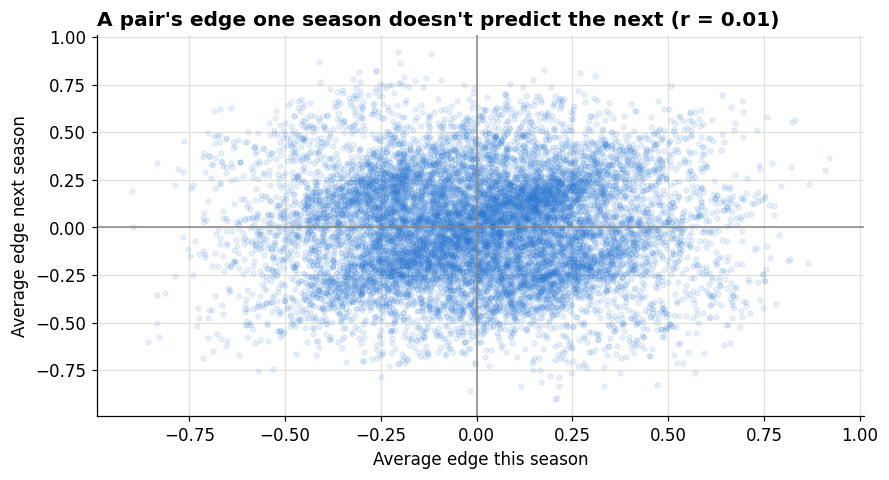

In [30]:
r = both["avg_edge"].corr(both["next_edge"])

plt.scatter(both["avg_edge"], both["next_edge"], alpha=0.1, s=10, color=BLUE)
plt.axhline(0, color=GRAY, linewidth=1)
plt.axvline(0, color=GRAY, linewidth=1)

plt.title(f"A pair's edge one season doesn't predict the next (r = {r:.2f})")
plt.xlabel("Average edge this season")
plt.ylabel("Average edge next season")
plt.savefig("edge_carryover_scatter.png", bbox_inches="tight")
plt.show()

1980-1994 0.004
1995-2004 -0.011
2005-2015 0.039


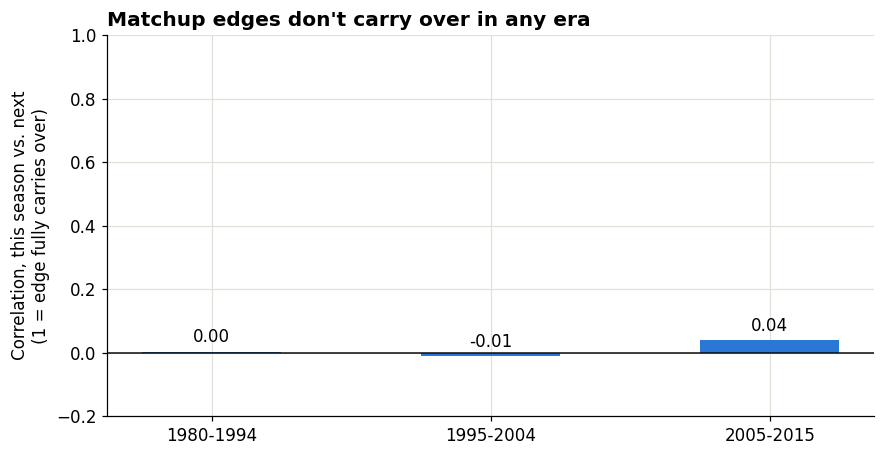

In [31]:
for era in ["1980-1994", "1995-2004", "2005-2015"]:
    subset = both[both["era"] == era]
    correlation = subset["avg_edge"].corr(subset["next_edge"])
    print(era, round(correlation, 3))



eras = ["1980-1994", "1995-2004", "2005-2015"]
corrs = []

for era in eras:
    subset = both[both["era"] == era]
    corrs.append(subset["avg_edge"].corr(subset["next_edge"]))

plt.bar(eras, corrs, color=BLUE, width=0.5)
plt.axhline(0, color=INK, linewidth=1)
plt.ylim(-0.2, 1)

for i, v in enumerate(corrs):
    plt.text(i, v + 0.03, f"{v:.2f}", ha="center")

plt.title("Matchup edges don't carry over in any era")
plt.ylabel("Correlation, this season vs. next\n(1 = edge fully carries over)")
plt.savefig("edge_carryover_by_era.png", bbox_inches="tight")
plt.show()

Observations:
- A pair's edges from one season do not carry over to the next season, because all the correlations from each era are values close to 0, and the graph shows no correlation.
- This visualization suggests that edges may depend on the current players and situation rather than the franchise, but we would need player-level data to confirm this.

Question 6: What should we ask next?
- A pair's edge in one season does not predict its edge the next season. The correlation is close to 0 in every era, so matchup edges do not typically last.
- Pair edges appear to be more spread out in the later eras, but that is likely because teams played each other fewer times per season, not because edges got stronger.